# 01 — Exploratory data analysis and target definition

**Goal of this notebook:** get to know the 30,000 credit card customers before building anything.
We want to know how many customers default, which columns look predictive, and what quirks
the data has that we must deal with.

Reminders from `CLAUDE.md`:
- one row = one credit card customer;
- `default = 1` means **bad** (the customer missed the October 2005 payment), `0` means good;
- `sex` and `marriage` are never used as model features.

In [1]:
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scorecard.data import clean, load_raw, save_processed
from scorecard.eda import (
    customers_with_negative_bill,
    default_rate_by,
    fixed_bands,
    negative_bill_summary,
    plot_default_rate,
    quantile_bands,
)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)
pd.set_option("display.max_columns", 30)
RATE_FORMAT = {"default_rate": "{:.1%}", "share": "{:.1%}"}

## 1. Load and clean

`clean()` fixes the known quirks (the log lines below show how many values it changed):
- `PAY_0` is renamed `pay_1`, so the six repayment columns run `pay_1` (September 2005) to `pay_6` (April 2005),
  the same numbering as `bill_amt1..6` and `pay_amt1..6`;
- undocumented `education` codes 0, 5 and 6 are grouped into 4 ("other");
- undocumented `marriage` code 0 is grouped into 3 ("other");
- all column names become lowercase;
- it checks that no customer appears twice and nothing is missing.

In [2]:
raw = load_raw()
df = clean(raw)
save_processed(df)
df.head()

INFO scorecard.data: Loaded 30000 rows x 25 columns from D:\Projects\Credit_analysis\data\raw\credit_card_default.csv


INFO scorecard.data: EDUCATION: recoded 345 values [0, 5, 6] -> 4


INFO scorecard.data: MARRIAGE: recoded 54 values [0] -> 3


INFO scorecard.data: Integrity check passed: 30000 unique customers, no missing values


INFO scorecard.data: Saved 30000 rows to D:\Projects\Credit_analysis\data\processed\clean.csv


,id,limit_bal,sex,education,marriage,age,pay_1,pay_2,pay_3,pay_4,pay_5,pay_6,bill_amt1,bill_amt2,bill_amt3,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Overall default rate

This is the **bad rate** of the whole portfolio, the baseline every group is compared with.
A group with a default rate well above it is riskier than average; well below it, safer.

In [3]:
overall_rate = df["default"].mean()
logging.info("Customers: %d | Defaults: %d | Default rate: %.2f%%",
             len(df), df["default"].sum(), 100 * overall_rate)

INFO root: Customers: 30000 | Defaults: 6636 | Default rate: 22.12%


About **22% of customers default**. That is far higher than a real bank's credit card book
(typically a few percent). The dataset was probably sampled so that defaults are well represented.
That's fine for learning, but the scorecard's probabilities won't match a real portfolio's.

## 3. Repayment status columns (`pay_1` … `pay_6`)

Each column records how the customer paid in one month:

| Value | Meaning |
|---|---|
| **-2** | No consumption: the card wasn't used / there was no balance to pay |
| **-1** | Paid in full ("pay duly") |
| **0** | Revolving credit: paid at least the minimum, but carried a balance |
| **1, 2, … 8** | Payment delayed by that many months (8 = eight months or more) |

The UCI documentation only describes -1 and 1–9. The meanings of -2 and 0 come from later
analysis of the data and are the widely accepted reading.

In [4]:
status_columns = [f"pay_{i}" for i in range(1, 7)]
status_counts = (
    pd.concat({c: df[c].value_counts() for c in status_columns}, axis=1)
    .sort_index().fillna(0).astype(int)
)
status_counts.index.name = "status"
status_counts

,pay_1,pay_2,pay_3,pay_4,pay_5,pay_6
status,,,,,,
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19


What this shows:
- Most customers are **0 (revolving)**, -1 (paid in full) or -2 (no use) every month. Only a minority are late.
- **Quirk:** status **1** ("one month late") occurs 3,688 times in `pay_1` but almost never in `pay_2`–`pay_6`
  (28, 4, 2, 0, 0). Older months seem to have been recorded differently, with customers who were one month late
  appearing as 0 or 2 instead. We can't fix this, but we must remember that **status 1 means something
  slightly different in the latest month than in older ones** when we bin these columns.
- Statuses 5–8 have very few customers, so we will group them when binning.

## 4. Default rate by most recent repayment status (`pay_1`)

This is usually the single strongest predictor in a behavioural scorecard. How a customer paid
last month says a lot about how they will pay next month.

In [5]:
by_pay_1 = default_rate_by(df, "pay_1")
by_pay_1.style.format(RATE_FORMAT)

,customers,defaults,default_rate,share
pay_1,,,,
-2,2759,365,13.2%,9.2%
-1,5686,954,16.8%,19.0%
0,14737,1888,12.8%,49.1%
1,3688,1252,33.9%,12.3%
2,2667,1844,69.1%,8.9%
3,322,244,75.8%,1.1%
4,76,52,68.4%,0.3%
5,26,13,50.0%,0.1%
6,11,6,54.5%,0.0%


INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


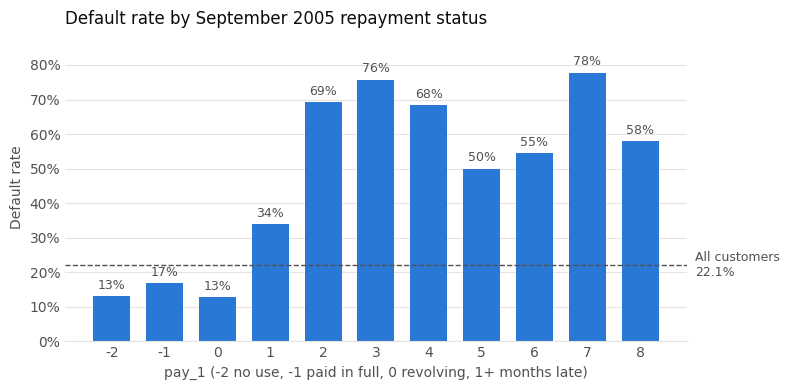

In [6]:
plot_default_rate(by_pay_1, "Default rate by September 2005 repayment status",
                  "pay_1 (-2 no use, -1 paid in full, 0 revolving, 1+ months late)", overall_rate)
plt.show()

- Customers who were **on time** (-2, -1, 0) default at about **13–17%**, below the 22% average.
- **One month late** jumps to about **34%**, and **two months late** to about **69%**.
  Missing payments is by far the clearest warning sign.
- The pattern is **not perfectly monotonic**. "Paid in full" (-1) defaults slightly *more* than "revolving" (0),
  and the rates for 4–8 bounce around because those groups have only 9–76 customers each.
  Binning (Step 3) will merge such groups so each bin has enough customers and a sensible risk order.

## 5. Default rate by credit limit and by age

**Credit limit (`limit_bal`)** is split into **quintiles**: five groups with roughly 20% of customers each.
Using quantiles instead of fixed amounts means no band ends up nearly empty.

In [7]:
by_limit = default_rate_by(df.assign(limit_band=quantile_bands(df["limit_bal"], q=5)), "limit_band")
by_limit.style.format(RATE_FORMAT)

,customers,defaults,default_rate,share
limit_band,,,,
"10,000-50,000",7676,2440,31.8%,25.6%
"50,000-100,000",4822,1244,25.8%,16.1%
"100,000-180,000",6123,1216,19.9%,20.4%
"180,000-270,000",5421,914,16.9%,18.1%
"270,000-1,000,000",5958,822,13.8%,19.9%


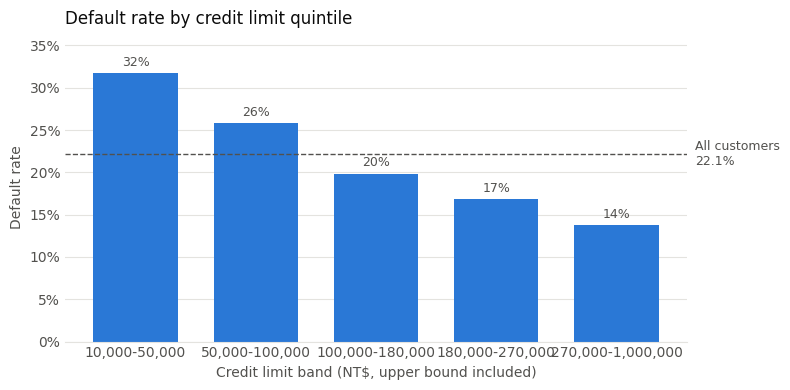

In [8]:
plot_default_rate(by_limit, "Default rate by credit limit quintile",
                  "Credit limit band (NT$, upper bound included)", overall_rate)
plt.show()

- Risk falls steadily as the limit rises, from about **32%** in the lowest band to about **14%** in the highest.
  Banks give bigger limits to customers they already trust, so the limit partly reflects the bank's own earlier risk judgement.
- The bands are **not exactly 20% each**. Many customers have round limits (for example exactly 50,000), and
  customers with the same limit can't be split across two bands.

**Age** is split into fixed bands. Age is a *sensitive* characteristic (see `CLAUDE.md`). We look at it here
to understand the data, but using it in the model would need a documented justification.

In [9]:
age_edges = [20, 25, 30, 35, 40, 50, 60, np.inf]
by_age = default_rate_by(df.assign(age_band=fixed_bands(df["age"], age_edges)), "age_band")
by_age.style.format(RATE_FORMAT)

,customers,defaults,default_rate,share
age_band,,,,
21-25,3871,1032,26.7%,12.9%
26-30,7142,1439,20.1%,23.8%
31-35,5796,1126,19.4%,19.3%
36-40,4917,1063,21.6%,16.4%
41-50,6005,1399,23.3%,20.0%
51-60,1997,504,25.2%,6.7%
61+,272,73,26.8%,0.9%


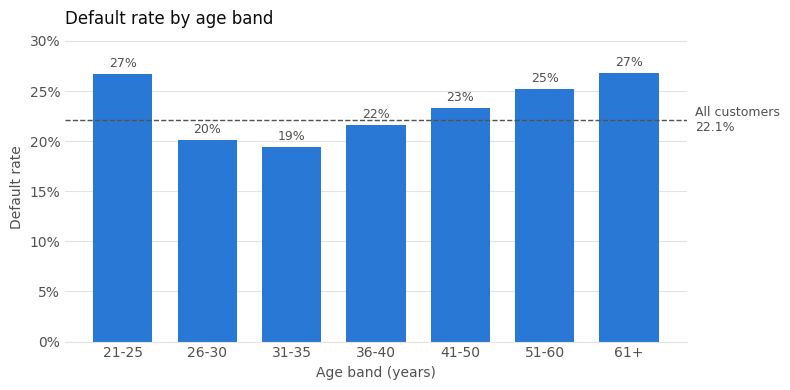

In [10]:
plot_default_rate(by_age, "Default rate by age band", "Age band (years)", overall_rate)
plt.show()

- The relationship is **U-shaped**. The youngest (21–25) and oldest (51+) customers default most (about 25–27%),
  and customers aged 26–40 default least (about 19–22%).
- The differences are much smaller than for repayment status, so age is a weak predictor here.
  Combined with the fairness concern, that is a good reason to leave it out of the scorecard.

## 6. Negative bill amounts

A bill amount (`bill_amt1..6`) is what the customer owed on the statement date. A **negative** bill means the
customer has a **credit balance**: they paid more than they owed or received a refund, so the bank owes *them* money.
This is legitimate, not a data error, but binning must give it a sensible place.

In [11]:
n_negative = customers_with_negative_bill(df)
logging.info("Customers with at least one negative bill: %d (%.1f%%)", n_negative, 100 * n_negative / len(df))
negative_bill_summary(df).style.format({"share": "{:.1%}"})

INFO root: Customers with at least one negative bill: 1930 (6.4%)


,negative_bills,share
bill_amt1,590,2.0%
bill_amt2,669,2.2%
bill_amt3,655,2.2%
bill_amt4,675,2.2%
bill_amt5,655,2.2%
bill_amt6,688,2.3%


In [12]:
has_negative_bill = (df[[f"bill_amt{i}" for i in range(1, 7)]] < 0).any(axis=1).rename("has_negative_bill")
default_rate_by(df.assign(has_negative_bill=has_negative_bill), "has_negative_bill").style.format(RATE_FORMAT)

,customers,defaults,default_rate,share
has_negative_bill,,,,
False,28070,6318,22.5%,93.6%
True,1930,318,16.5%,6.4%


- About **6% of customers** have at least one negative bill, about 2% in any single month.
- They default **less** than everyone else (about 16% vs 23%), which makes sense: having a credit balance is a sign of
  paying ahead, not falling behind.

## 7. Observation and performance windows

A behavioural scorecard predicts the **future** from the **past**, so the timeline must be split cleanly:

```
 Apr   May   Jun   Jul   Aug   Sep  |  Oct 2005
 └──────── observation window ────┘ |  performance window
   pay_6 … pay_1                    |  default = 1 if the
   bill_amt6 … bill_amt1            |  October payment
   pay_amt6 … pay_amt1              |  was missed
```

- **Observation window (April–September 2005):** the six months of behaviour we are allowed to use as features:
  repayment status, bills and payments. Column number 1 is the most recent month (September), 6 the oldest (April).
- **Performance window (October 2005):** the period in which we watch whether the customer turns "bad".
  The target `default` is measured here.

Why this matters: no information from the performance window may leak into the features. If it did, the model
would look brilliant in testing and fail in real use, where the future is unknown.

One limitation: real banks usually use a performance window of **12 months** and define "bad" as *90+ days past due*.
Here we only have **one month** and a simple yes/no default flag, so our target measures short-term risk.